# MOSH abstract figures

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "../")

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

In [2]:
# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 85
dose_grid_half_mosh = 2.5 # cm

# Z coordinate of radioactive source - set in TOPAS parameter files
source_transZ_mosh = -0.5 # cm

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

In [3]:
# Assume dose point in center of ROI
dose_point = (0.0, 0.5)

# Applicator radius - set in TOPAS parameter files
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # cm

# 0 = x, 1 = y, 2 = z
const_axis = 2

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-1.5, 1.5)
rngY = (-1.5, 1.5)

### MOSH - 1 rod removed @ position 1

In [4]:
mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"

source_plane = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, lattice_mosh)

dose_point_energy, dose_point_voxel = extract_norm_energy(mosh, source_plane, const_axis, dose_point, bins_mosh, lattice_mosh)

dose = 100 # % of dose

In [6]:
X, Y, energy0, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=True, norm_energy=dose_point_energy, dose=dose, zero_source=True, std_dev=True)

Text(0, 0.5, '$y$ (cm)')

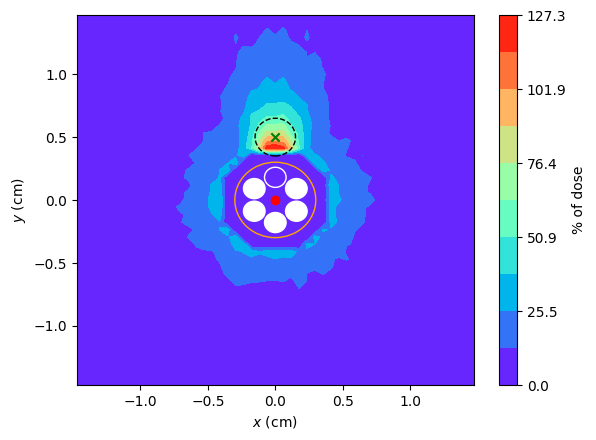

In [6]:
fig0, ax0 = plt.subplots()
Xv, Yv = np.meshgrid(X, Y, indexing='ij')

# Draw contour plot
contour0 = ax0.contourf(Xv, Yv, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar0 = fig0.colorbar(contour0, label="% of dose")

# Draw applicator
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="orange", fill=False)
ax0.add_patch(circle)

# Draw ROI
circle2 = plt.Circle((0, 0.5), radius=0.15, edgecolor="black", linestyle="--", fill=False)
ax0.add_patch(circle2)

# Draw shielding channels, radius = 0.08 cm
channel1 = plt.Circle((0, 0.18), radius=0.08, edgecolor="white", fill=False) # empty
ax0.add_patch(channel1)
channel2 = plt.Circle((0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax0.add_patch(channel2)
channel3 = plt.Circle((0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax0.add_patch(channel3)
channel4 = plt.Circle((0, -0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax0.add_patch(channel4)
channel5 = plt.Circle((-0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax0.add_patch(channel5)
channel6 = plt.Circle((-0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax0.add_patch(channel6)

# Label dose point at center of ROI
ax0.scatter(dose_point[0], dose_point[1], color="green", marker="x")

# Label source
ax0.scatter(0, 0, color="red", marker="o")

ax0.set_xlabel(r"$x$ (cm)")
ax0.set_ylabel(r"$y$ (cm)")

Fig 1: dose distribution with rod adjacent to the ROI removed. Legend: red dot - source; white circles - shielding channels/rods; orange circle - applicator edge; green x - normalization point; dashed black circle - ROI boundary.

### MOSH - 6 rods inserted

In [7]:
#comparison = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/6rods_1e7_85bins_2.5cmHL.csv"

comparison = "/Users/seanmullane/Desktop/Research_2023/abstract_submission/hollow_cylinder_Ti/hollow_cylinder_output.csv"

dose_point_energy2, dose_point_voxel2 = extract_norm_energy(comparison, source_plane, const_axis, dose_point, bins_mosh, lattice_mosh)

In [8]:
X, Y, energy1, std_dev = contour_energy(comparison, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=True, norm_energy=dose_point_energy2, dose=dose, zero_source=True, std_dev=True)

Text(0, 0.5, '$y$ (cm)')

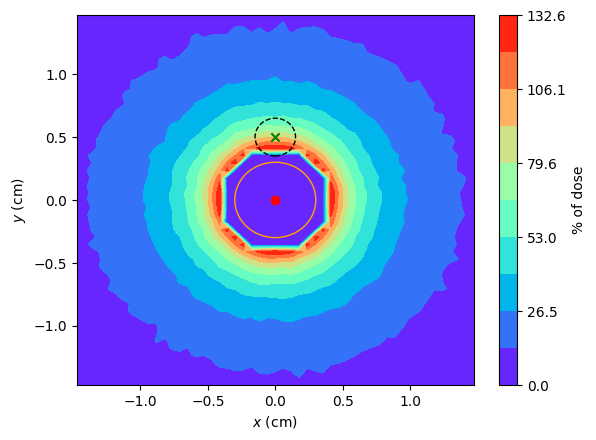

In [9]:
fig1, ax1 = plt.subplots()

# Draw contour plot
contour1 = ax1.contourf(Xv, Yv, energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1, label="% of dose")

# Draw applicator
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="orange", fill=False)
ax1.add_patch(circle)

# Draw ROI
circle2 = plt.Circle((0, 0.5), radius=0.15, edgecolor="black", linestyle="--", fill=False)
ax1.add_patch(circle2)

# Draw shielding channels, radius = 0.08 cm
"""
channel1 = plt.Circle((0, 0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel1)
channel2 = plt.Circle((0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel2)
channel3 = plt.Circle((0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel3)
channel4 = plt.Circle((0, -0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel4)
channel5 = plt.Circle((-0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel5)
channel6 = plt.Circle((-0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
ax1.add_patch(channel6)
"""

# Label dose point at center of ROI
ax1.scatter(dose_point[0], dose_point[1], color="green", marker="x")

# Label source
ax1.scatter(0, 0, color="red", marker="o")

ax1.set_xlabel(r"$x$ (cm)")
ax1.set_ylabel(r"$y$ (cm)")

Fig 2: dose distribution without modulated shielding. Legend same as Fig 1.

### Energy @ constant radius = 0.5 cm

In [10]:
theta = pi
error = 0.029
rad = 0.50 # cm

# 1 rod removed
linear_energy_1, eng_at_const_r_1 = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, radius=rad, scale=True, norm_energy=dose_point_energy, dose=dose)

# No rods removed
linear_energy_2, eng_at_const_r_2 = energy_along_theta(comparison, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, radius=rad, scale=True, norm_energy=dose_point_energy2, dose=dose)

In [11]:
# 1 rod removed
x_theta_1, y_energy_1, std_dev_1, __, __ = plotter_1D(eng_at_const_r_1, ind_var=1, plot_rng=(0,0), std_dev=True, num_Hx=1e7)

# No rods removed
x_theta_2, y_energy_2, std_dev_2, __, __ = plotter_1D(eng_at_const_r_2, ind_var=1, plot_rng=(0,0), std_dev=True, num_Hx=1e7)

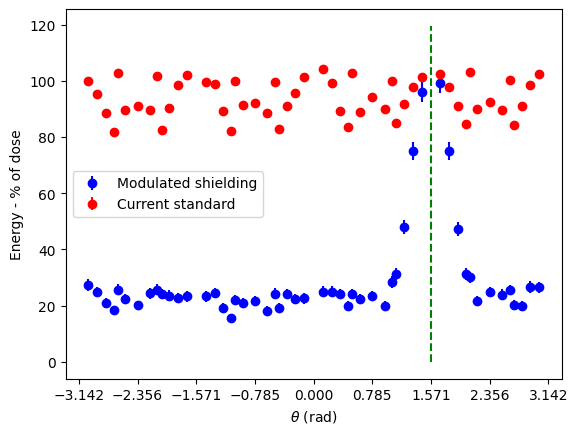

In [12]:
fig2, ax2 = plt.subplots()
ax2.errorbar(x_theta_1, y_energy_1, yerr=std_dev_1, fmt="bo", label="Modulated shielding")
ax2.errorbar(x_theta_2, y_energy_2, yerr=std_dev_2, fmt="ro", label="Current standard")
#ax2.scatter(x_theta_1, y_energy_1, marker="x")
#ax2.scatter(x_theta_2, y_energy_2, color="red")

ybar = np.arange(0, 120, step=0.5)
xbar = np.ones(np.shape(ybar))*pi/2
ax2.plot(xbar, ybar, color="green", linestyle="--")

ax2.xaxis.set_major_locator(plt.MultipleLocator(np.pi/4))

ax2.set_xlabel(r"$\theta$ (rad)")
ax2.set_ylabel(r"Energy - % of dose")
ax2.legend(loc="center left")

### Compare average energy at r = 0.5 cm

In [13]:
# We include the region -pi to pi/4
# 1 rod removed
combined_1 = np.vstack((x_theta_1, y_energy_1))

#b1 = (combined_1[0, :] >= -pi) & (combined_1[0,:] <= pi/4)

temp_1 = ((combined_1[0, :] >= -pi) & (combined_1[0,:] <= pi/4))
temp_2 = ((combined_1[0,:] <= pi) & (combined_1[0,:] >= 3*pi/4)) 

b1 = np.logical_or(temp_1, temp_2)

avg_mosh = np.average(combined_1[1,:][b1])
print("average energy mosh = " + str(avg_mosh) + "%")

# Error propagation assuming independence between voxels
# This may not be a great assumption - something to explore later?
def error_prop_avg(std_dev_array):
   return (1/np.shape(std_dev_array)[0])*np.sqrt(np.sum(std_dev_array**2))

avg_mosh_error = error_prop_avg(std_dev_1)
print("propagated error = " + str(avg_mosh_error) + "%")

average energy mosh = 22.83519264503013%
propagated error = 0.28074904531188927%


In [23]:
# No rods removed
combined_2 = np.vstack((x_theta_2, y_energy_2))

#b2 = (combined_2[0, :] >= -pi) & (combined_2[0,:] <= pi/4)

temp_3 = ((combined_1[0, :] >= -pi) & (combined_1[0,:] <= pi/4))
temp_4 = ((combined_1[0,:] <= pi) & (combined_1[0,:] >= 3*pi/4)) 

b2 = np.logical_or(temp_3, temp_4)

avg_standard = np.average(combined_2[1,:][b2])
print("average energy standard = " + str(avg_standard) + "%")

avg_standard_error = error_prop_avg(std_dev_2)
print("propagated error = " + str(avg_standard_error) + "%")

average energy standard = 93.64600386134148%
propagated error = 0.18489197053749865%


### Energy @ constant angle = 0

In [15]:
# 1 rod removed
x_rad_1, y_constr_energy_1, const_r_std_1, __, __ = plotter_1D(linear_energy_1, ind_var=0, plot_rng=(0.3,2.0), std_dev=True, num_Hx=1e7)

# No rods removed
x_rad_2, y_constr_energy_2, const_r_std_2, __, __ = plotter_1D(linear_energy_2, ind_var=0, plot_rng=(0.3,2.0), std_dev=True, num_Hx=1e7)

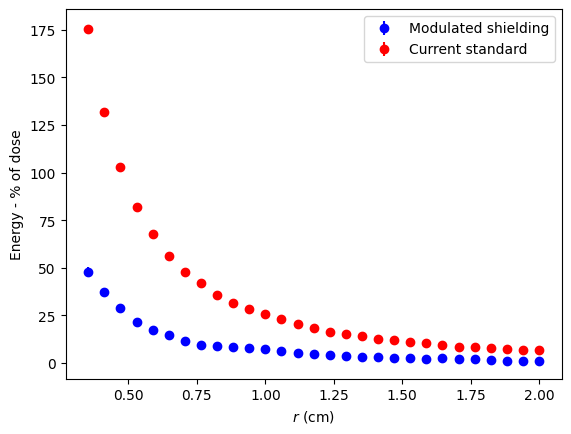

In [16]:
fig3, ax3 = plt.subplots()
ax3.errorbar(x_rad_1, y_constr_energy_1, yerr=const_r_std_1, fmt="bo", label="Modulated shielding")
ax3.errorbar(x_rad_2, y_constr_energy_2, yerr=const_r_std_2, fmt="ro", label="Current standard")

ax3.set_xlabel(r"$r$ (cm)")
ax3.set_ylabel(r"Energy - % of dose")
ax3.legend()

### Computing reduction in dose at different radii

In [17]:
radii = np.array([0.35, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.0, 1.5, 2.0, 2.5])

def compute_avg_energy(theta, energy):
    combined = np.vstack((theta, energy))
    
    #bool = (combined[0, :] >= -pi) & (combined[0,:] <= pi/4)
    
    temp_a = ((combined[0, :] >= -pi) & (combined[0,:] <= pi/4))
    temp_b = ((combined[0,:] <= pi) & (combined[0,:] >= 3*pi/4)) 

    bool = np.logical_or(temp_a, temp_b)
    
    return np.average(combined[1,:][bool])

In [18]:
# 1 rod removed
one_rod_removed_eng = np.array([])
one_rod_removed_std = np.array([])
for r in radii:
    __, eng_at_const_r = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, radius=r, scale=True, norm_energy=dose_point_energy, dose=dose)

    theta_arr, energy_arr, std_dev_arr, __, __ = plotter_1D(eng_at_const_r, ind_var=1, plot_rng=(0,0), std_dev=True, num_Hx=1e7)
    
    avg = compute_avg_energy(theta_arr, energy_arr)
    prop_error = error_prop_avg(std_dev_arr)
    one_rod_removed_eng = np.append(one_rod_removed_eng, avg)
    one_rod_removed_std = np.append(one_rod_removed_std, prop_error)

print(one_rod_removed_eng)
print(one_rod_removed_std)

[43.40427554 33.57243982 22.83519265 15.91159035 11.88789984  9.41439792
  7.43502105  5.97298563  2.65671876  1.53760696  0.97536893]
[0.45405905 0.3280137  0.28074905 0.21380391 0.17992985 0.15177917
 0.1182713  0.09815222 0.05653667 0.03442615 0.02498628]


In [19]:
# No rods removed
all_rods_eng = np.array([])
all_rods_std = np.array([])

for r2 in radii:
    __, eng_at_const_r_2 = energy_along_theta(comparison, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, radius=r2, scale=True, norm_energy=dose_point_energy2, dose=dose)

    theta_arr_2, energy_arr_2, std_dev_arr_2, __, __ = plotter_1D(eng_at_const_r_2, ind_var=1, plot_rng=(0,0), std_dev=True, num_Hx=1e7)
    
    avg_2 = compute_avg_energy(theta_arr_2, energy_arr_2)
    prop_error_2 = error_prop_avg(std_dev_arr_2)
    all_rods_eng = np.append(all_rods_eng, avg_2)
    all_rods_std = np.append(all_rods_std, prop_error_2)

print(all_rods_eng)
print(all_rods_std)

[177.09924538 137.92031627  93.64600386  65.5713835   47.68399437
  37.65198738  30.41532602  24.50353474  11.4351026    6.55287062
   4.28533581]
[0.29430324 0.2164238  0.18489197 0.13940006 0.11516995 0.0967737
 0.07720134 0.06394498 0.03749483 0.02292411 0.01699784]


In [20]:
# Compute percent difference
def perc_diff(mosh, compare):
    return (mosh - compare)/compare

diff = perc_diff(one_rod_removed_eng, all_rods_eng)
print(diff)
print(np.average(diff))

[-0.75491553 -0.7565809  -0.75615412 -0.75733941 -0.75069413 -0.74996279
 -0.75555018 -0.75623984 -0.76766988 -0.76535368 -0.77239382]
-0.7584412963509752


### Stacking contour plots

Text(0.5, 0, '$x$ (cm)')

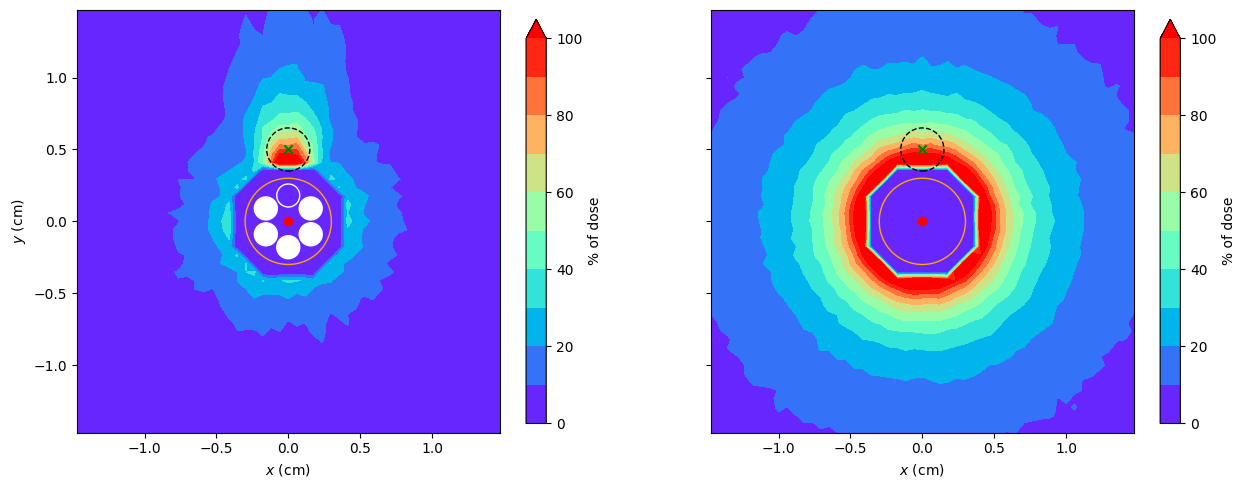

In [21]:
#### Set up basic contour plots ####
fig4, axs4 = plt.subplots(1, 2, sharey=True, figsize=(15, 15))

axs4[0].set_box_aspect(1)
axs4[1].set_box_aspect(1)

levels = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100])

#contour00 = axs4[0].contourf(Xv, Yv, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
#contour01 = axs4[1].contourf(Xv, Yv, energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")

contour00 = axs4[0].contourf(Xv, Yv, energy0, locator=ticker.LinearLocator(), vmin=0, vmax=100, cmap="rainbow", levels=levels, extend='max')
contour01 = axs4[1].contourf(Xv, Yv, energy1, locator=ticker.LinearLocator(), vmin=0, vmax=100, cmap="rainbow", levels=levels, extend='max')

cbar = fig4.colorbar(contour00, label="% of dose", shrink=0.35, extend='max')
cbar = fig4.colorbar(contour01, label="% of dose", shrink=0.35, extend='max')

#### 1 rod removed ####
# Draw applicator
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="orange", fill=False)
axs4[0].add_patch(circle)

# Draw ROI
circle2 = plt.Circle((0, 0.5), radius=0.15, edgecolor="black", linestyle="--", fill=False)
axs4[0].add_patch(circle2)

# Draw shielding channels, radius = 0.08 cm
channel1 = plt.Circle((0, 0.18), radius=0.08, edgecolor="white", fill=False) # empty
axs4[0].add_patch(channel1)
channel2 = plt.Circle((0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[0].add_patch(channel2)
channel3 = plt.Circle((0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[0].add_patch(channel3)
channel4 = plt.Circle((0, -0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[0].add_patch(channel4)
channel5 = plt.Circle((-0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[0].add_patch(channel5)
channel6 = plt.Circle((-0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[0].add_patch(channel6)

# Label dose point at center of ROI
axs4[0].scatter(dose_point[0], dose_point[1], color="green", marker="x")

# Label source
axs4[0].scatter(0, 0, color="red", marker="o")

axs4[0].set_xlabel(r"$x$ (cm)")
axs4[0].set_ylabel(r"$y$ (cm)")

#### No rods removed ####
# Draw applicator
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="orange", fill=False)
axs4[1].add_patch(circle)

# Draw ROI
circle2 = plt.Circle((0, 0.5), radius=0.15, edgecolor="black", linestyle="--", fill=False)
axs4[1].add_patch(circle2)

# Draw shielding channels, radius = 0.08 cm
"""
channel1 = plt.Circle((0, 0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel1)
channel2 = plt.Circle((0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel2)
channel3 = plt.Circle((0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel3)
channel4 = plt.Circle((0, -0.18), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel4)
channel5 = plt.Circle((-0.156, -0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel5)
channel6 = plt.Circle((-0.156, 0.09), radius=0.08, edgecolor="white", facecolor="white", fill=True) # filled
axs4[1].add_patch(channel6)
"""

# Label dose point at center of ROI
axs4[1].scatter(dose_point[0], dose_point[1], color="green", marker="x")

# Label source
axs4[1].scatter(0, 0, color="red", marker="o")

axs4[1].set_xlabel(r"$x$ (cm)")